# IMC-HistoTools Tutorial 3: three-color virtual IHC of HCC

In [2]:
import os, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tifffile

# ---- Load the IMC_HistoTools package (repository root) ----
IMC_HistoTools_path = "/Users/gjhan/Documents/GitHub/Whole-Slide_IMC"
if IMC_HistoTools_path not in sys.path:
    sys.path.insert(0, IMC_HistoTools_path)

import IMC_HistoTools
from IMC_HistoTools.virtual_IHC import virtual_IHC, virtual_IHC_ROI
from IMC_HistoTools.annotation_region import virtual_IHC_annotation, Hscore_threshold

out_dir = Path("/Users/gjhan/Documents/Papers_submit/Selenium/Data/261013_IMC_HistoTools")
out_dir.mkdir(parents=True, exist_ok=True)

print("IMC_HistoTools version:", IMC_HistoTools.__version__)
print("output dir:", out_dir)

IMC_HistoTools version: 0.1.0
output dir: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261013_IMC_HistoTools


In [16]:
input_dir = Path("/Users/gjhan/Documents/Papers_submit/Selenium/Data/261014_Panel_TM_Se_aSMA/analysis/05_background_correction")
output_dir =Path("/Users/gjhan/Documents/Papers_submit/Selenium/Data/261014_Panel_TM_Se_aSMA/analysis/06_virtual_IHC")
αSMA = tifffile.imread(input_dir / "ROI_001_Se_aSMA_cor.tiff").astype(np.float32)
DNA_1 = tifffile.imread(input_dir / "ROI_001_191Ir-DNA_Ir191_cor.tiff").astype(np.float32)
DNA_2 = tifffile.imread(input_dir / "ROI_001_193Ir-DNA_Ir193_cor.tiff").astype(np.float32)

marker = tifffile.imread(input_dir / "ROI_001_141Pr-EP-CAM_Pr141_cor.tiff").astype(np.float32)
print("αSMA :", αSMA.shape)

αSMA : (2560, 4812)


Blue  image: DNA,  shape: (2560, 4812), dtype: float32
Red   image: αSMA,   shape: (2560, 4812), dtype: float32
Brown image: Keratin8-18, shape: (2560, 4812), dtype: float32


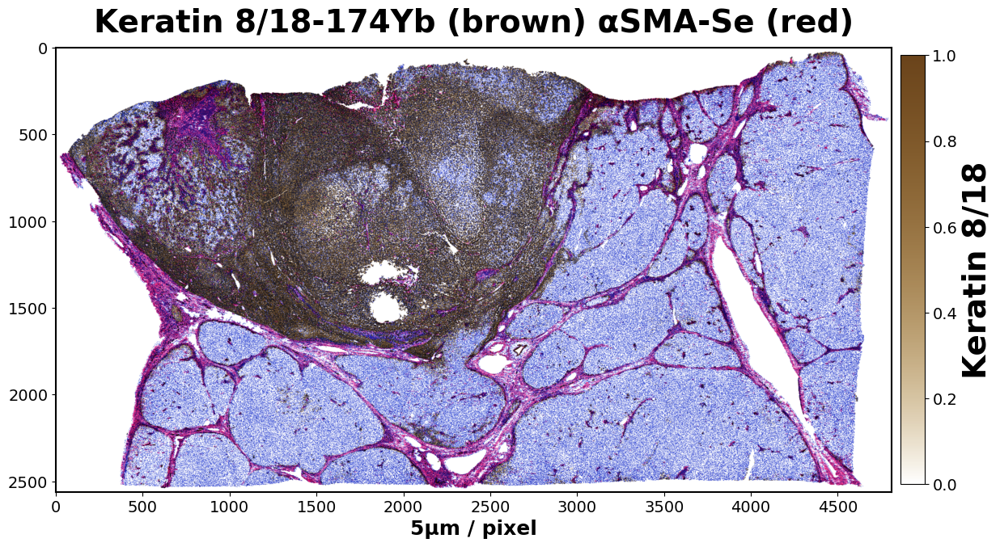

Figure saved to: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261014_Panel_TM_Se_aSMA/analysis/06_virtual_IHC/αSMA_174Yb-Keratin8-18.png  (dpi=300)
Raw image saved to: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261014_Panel_TM_Se_aSMA/analysis/06_virtual_IHC/αSMA_174Yb-Keratin8-18_raw.tiff


In [17]:
# virtual IHC from Keratin8-18-174Yb, αSMA-Se, DNA-Ir
marker = tifffile.imread(input_dir / "ROI_001_174Yb-Keratin8-18_Yb174_cor.tiff").astype(np.float32)

# ---- Virtual IHC (HCC) ----
fig = virtual_IHC(Blue_image=DNA_1+DNA_2, Red_image=αSMA, Brown_image=marker,  
                  blue_name="DNA", brown_name="Keratin8-18", red_name="αSMA",
                  red_threshold=0.1,
                  brown_threshold=0,
                  title="Keratin 8/18-174Yb (brown) αSMA-Se (red)", 
                  xlabel='5μm / pixel',
                  ylabel='',
                  sigma=1, kernel_size=(3, 3),
                  k1=0.15,k2=0.15, k3=0.25,
                  figsize=(12, 6.8),
                  tick_step=500, xlim=(0, αSMA.shape[1]), ylim=(0, αSMA.shape[0]),
                  tick_fontsize=14,
                  tick_fontweight='normal',
                  axis_label_fontsize=18,
                  axis_label_fontweight='bold',  
                  title_fontsize=28,
                  title_fontweight='bold',
                  title_pad=14,
                  bar_pad=0.01, 
                  brown_bar=True,
                  bar_spacing=0.15,
                  red_bar_depth=1.0,
                  brown_bar_label='Keratin 8/18',
                  bar_fraction=0.02453,
                  bar_shrink=0.93,
                  bar_label_fontsize=28,
                  bar_label_fontweight='bold',
                  bar_tick_fontsize=14,
                  save_dir=str(output_dir / "αSMA_174Yb-Keratin8-18.png"),
                  Save_raw=True,
                  save_dpi=300)

Blue  image: DNA,  shape: (2560, 4812), dtype: float32
Red   image: αSMA,   shape: (2560, 4812), dtype: float32
Brown image: HSP70, shape: (2560, 4812), dtype: float32


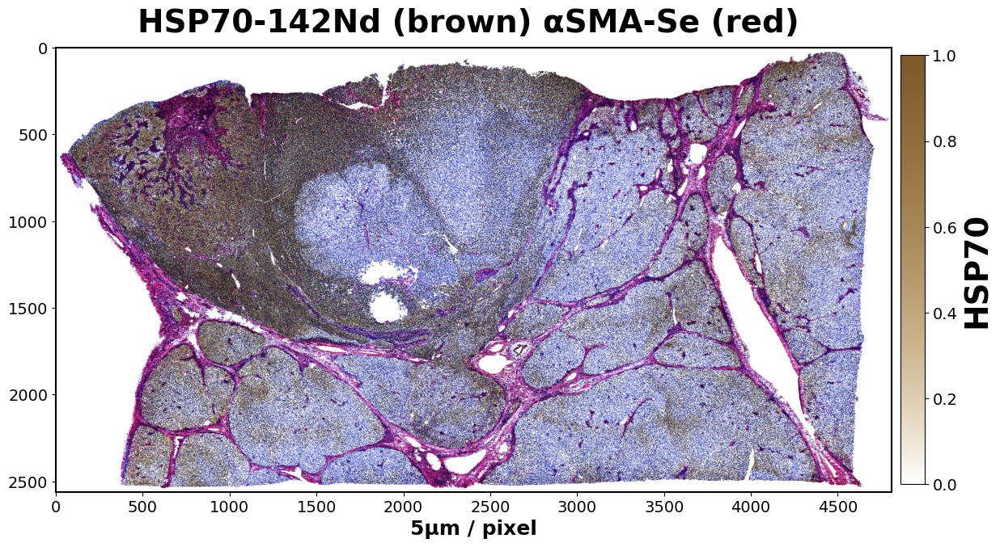

Figure saved to: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261014_Panel_TM_Se_aSMA/analysis/06_virtual_IHC/αSMA_142Nd-HSP70.png  (dpi=300)
Raw image saved to: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261014_Panel_TM_Se_aSMA/analysis/06_virtual_IHC/αSMA_142Nd-HSP70_raw.tiff


In [11]:
# virtual IHC from HSP70-142Nd, αSMA-Se, DNA-Ir
marker = tifffile.imread(input_dir / "ROI_001_142Nd-HSP70_Nd142_cor.tiff").astype(np.float32)

# ---- Virtual IHC (HCC) ----
fig = virtual_IHC(Blue_image=DNA_1+DNA_2, Red_image=αSMA, Brown_image=marker,  
                  blue_name="DNA", brown_name="HSP70", red_name="αSMA",
                  red_threshold=0.1,
                  brown_threshold=0.1,
                  title="HSP70-142Nd (brown) αSMA-Se (red) ", 
                  xlabel='5μm / pixel',
                  ylabel='',
                  sigma=1, kernel_size=(3, 3),
                  k1=0.15,k2=0.15, k3=0.2,
                  figsize=(12, 6.8),
                  tick_step=500, xlim=(0, αSMA.shape[1]), ylim=(0, αSMA.shape[0]),
                  tick_fontsize=14,
                  tick_fontweight='normal',
                  axis_label_fontsize=18,
                  axis_label_fontweight='bold',  
                  title_fontsize=28,
                  title_fontweight='bold',
                  title_pad=14,
                  bar_pad=0.01,
                  brown_bar=True,
                  brown_bar_label='HSP70',
                  bar_fraction=0.02453,
                  bar_shrink=0.93,
                  bar_label_fontsize=28,
                  bar_label_fontweight='bold',
                  bar_tick_fontsize=14,
                  save_dir=str(output_dir / "αSMA_142Nd-HSP70.png"),
                  Save_raw=True,
                  save_dpi=300)

Blue  image: DNA,  shape: (2560, 4812), dtype: float32
Red   image: αSMA,   shape: (2560, 4812), dtype: float32
Brown image: GPC3, shape: (2560, 4812), dtype: float32


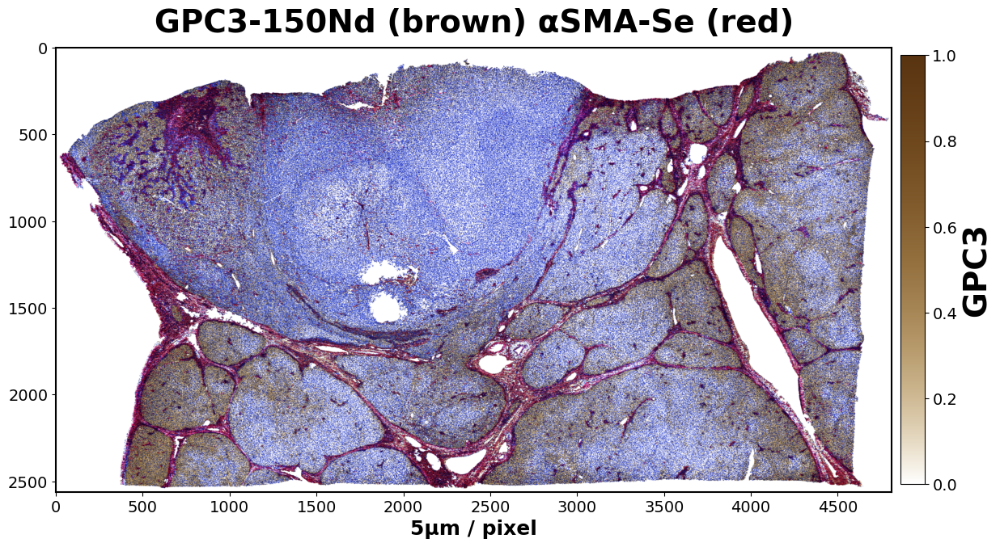

Figure saved to: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261014_Panel_TM_Se_aSMA/analysis/06_virtual_IHC/αSMA_150Nd-GPC3.png  (dpi=300)
Raw image saved to: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261014_Panel_TM_Se_aSMA/analysis/06_virtual_IHC/αSMA_150Nd-GPC3_raw.tiff


In [14]:
marker = tifffile.imread(input_dir / "ROI_001_150Nd-GPC3_Nd150_cor.tiff").astype(np.float32)

# ---- Virtual IHC (HCC) ----
fig = virtual_IHC(Blue_image=DNA_1+DNA_2, Red_image=αSMA, Brown_image=marker,  
                  blue_name="DNA", brown_name="GPC3", red_name="αSMA",
                  red_threshold=0.1,
                  brown_threshold=0.1,
                  title="GPC3-150Nd (brown) αSMA-Se (red)", 
                  xlabel='5μm / pixel',
                  ylabel='',
                  sigma=1, kernel_size=(3, 3),
                  k1=0.15,k2=0.15, k3=0.3,
                  figsize=(12, 6.8),
                  tick_step=500, xlim=(0, αSMA.shape[1]), ylim=(0, αSMA.shape[0]),
                  tick_fontsize=14,
                  tick_fontweight='normal',
                  axis_label_fontsize=18,
                  axis_label_fontweight='bold',  
                  title_fontsize=28,
                  title_fontweight='bold',
                  title_pad=14,
                  bar_pad=0.01, 
                  brown_bar=True,
                  brown_bar_label='GPC3',
                  bar_fraction=0.02453,
                  bar_shrink=0.93,
                  bar_label_fontsize=28,
                  bar_label_fontweight='bold',
                  bar_tick_fontsize=14,
                  save_dir=str(output_dir / "αSMA_150Nd-GPC3.png"),
                  Save_raw=True,
                  save_dpi=300)

Blue  image: DNA,  shape: (2560, 4812), dtype: float32
Red   image: αSMA,   shape: (2560, 4812), dtype: float32
Brown image: VEGF, shape: (2560, 4812), dtype: float32


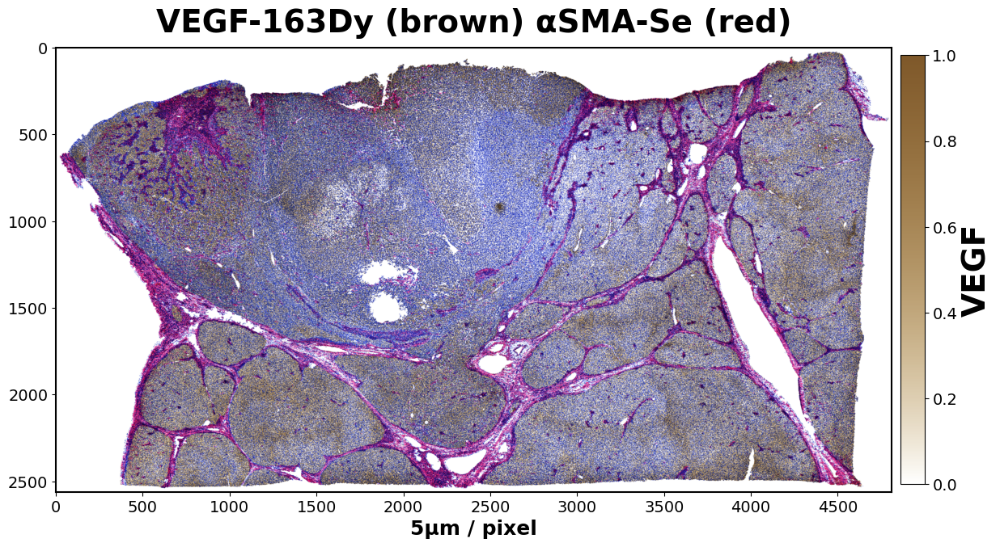

Figure saved to: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261014_Panel_TM_Se_aSMA/analysis/06_virtual_IHC/αSMA_163Dy-VEGF.png  (dpi=300)
Raw image saved to: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261014_Panel_TM_Se_aSMA/analysis/06_virtual_IHC/αSMA_163Dy-VEGF_raw.tiff


In [13]:
marker = tifffile.imread(input_dir / "ROI_001_163Dy-VEGF_Dy163_cor.tiff").astype(np.float32)

# ---- Virtual IHC (HCC) ----
fig = virtual_IHC(Blue_image=DNA_1+DNA_2, Red_image=αSMA, Brown_image=marker,  
                  blue_name="DNA", brown_name="VEGF", red_name="αSMA",
                  red_threshold=0.1,
                  brown_threshold=0.3,
                  title="VEGF-163Dy (brown) αSMA-Se (red)", 
                  xlabel='5μm / pixel',
                  ylabel='',
                  sigma=1, kernel_size=(3, 3),
                  k1=0.15,k2=0.15, k3=0.2,
                  figsize=(12, 6.8),
                  tick_step=500, xlim=(0, αSMA.shape[1]), ylim=(0, αSMA.shape[0]),
                  tick_fontsize=14,
                  tick_fontweight='normal',
                  axis_label_fontsize=18,
                  axis_label_fontweight='bold',  
                  title_fontsize=28,
                  title_fontweight='bold',
                  title_pad=14,
                  bar_pad=0.01,
                  brown_bar=True,
                  brown_bar_label='VEGF',
                  bar_fraction=0.02453,
                  bar_shrink=0.93,
                  bar_label_fontsize=28,
                  bar_label_fontweight='bold',
                  bar_tick_fontsize=14,
                  save_dir=str(output_dir / "αSMA_163Dy-VEGF.png"),
                  Save_raw=True,
                  save_dpi=300)

Blue  image: DNA,  shape: (2560, 4812), dtype: float32
Red   image: αSMA,   shape: (2560, 4812), dtype: float32
Brown image: GS, shape: (2560, 4812), dtype: float32


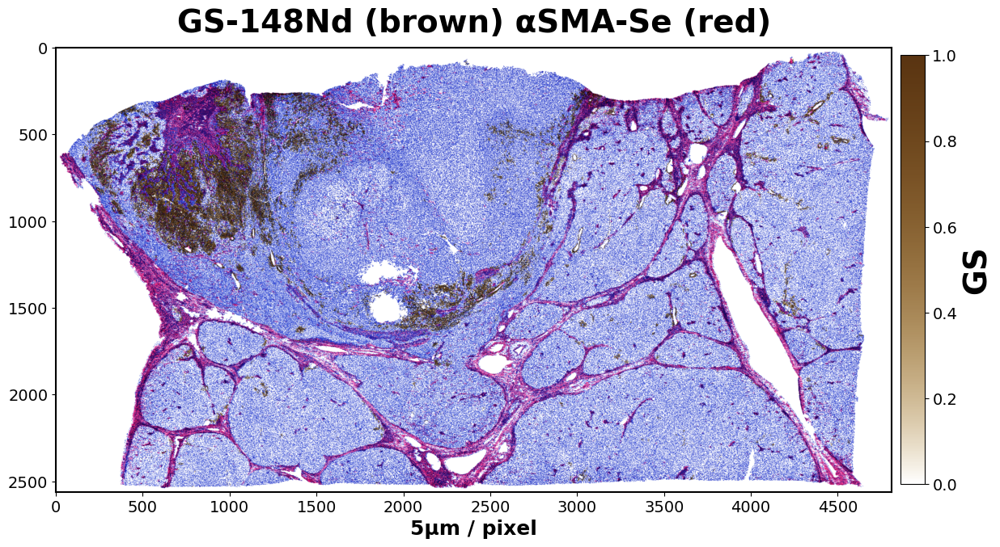

Figure saved to: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261014_Panel_TM_Se_aSMA/analysis/06_virtual_IHC/αSMA_148Nd-GS.png  (dpi=300)
Raw image saved to: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261014_Panel_TM_Se_aSMA/analysis/06_virtual_IHC/αSMA_148Nd-GS_raw.tiff


In [4]:
# virtual IHC from GS-148Nd, αSMA-Se, DNA-Ir
marker = tifffile.imread(input_dir / "ROI_001_148Nd-GS_Nd148_cor.tiff").astype(np.float32)

# ---- Virtual IHC (HCC) ----
fig = virtual_IHC(Blue_image=DNA_1+DNA_2, Red_image=αSMA, Brown_image=marker,  
                  blue_name="DNA", brown_name="GS", red_name="αSMA",
                  red_threshold=0.1,
                  brown_threshold=0,
                  title="GS-148Nd (brown) αSMA-Se (red)", 
                  xlabel='5μm / pixel',
                  ylabel='',
                  sigma=1, kernel_size=(3, 3),
                  k1=0.15,k2=0.15, k3=0.3,
                  figsize=(12, 6.8),
                  tick_step=500, xlim=(0, αSMA.shape[1]), ylim=(0, αSMA.shape[0]),
                  tick_fontsize=14,
                  tick_fontweight='normal',
                  axis_label_fontsize=18,
                  axis_label_fontweight='bold',  
                  title_fontsize=28,
                  title_fontweight='bold',
                  title_pad=14,
                  bar_pad=0.01,
                  brown_bar=True,
                  brown_bar_label='GS',
                  bar_fraction=0.02453,
                  bar_shrink=0.93,
                  bar_label_fontsize=28,
                  bar_label_fontweight='bold',
                  bar_tick_fontsize=14,
                  save_dir=str(output_dir / "αSMA_148Nd-GS.png"),
                  Save_raw=True,
                  save_dpi=300)

Blue  image: DNA,  shape: (2560, 4812), dtype: float32
Red   image: αSMA,   shape: (2560, 4812), dtype: float32
Brown image: TIM-3, shape: (2560, 4812), dtype: float32


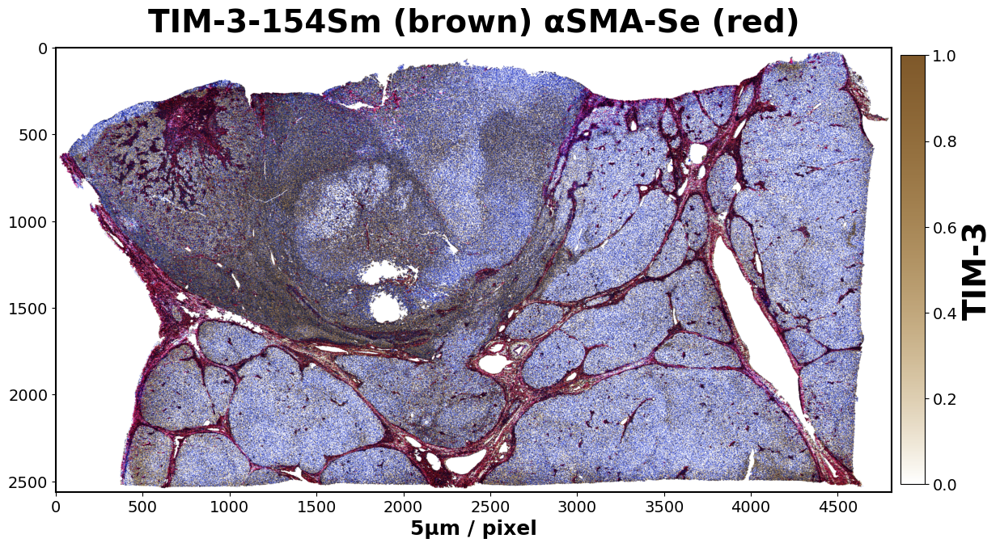

Figure saved to: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261014_Panel_TM_Se_aSMA/analysis/06_virtual_IHC/αSMA_154Sm-TIM-3.png  (dpi=300)
Raw image saved to: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261014_Panel_TM_Se_aSMA/analysis/06_virtual_IHC/αSMA_154Sm-TIM-3_raw.tiff


In [6]:
# virtual IHC from TIM-3-154Sm, αSMA-Se, DNA-Ir
marker = tifffile.imread(input_dir / "ROI_001_154Sm-TIM-3_Sm154_cor.tiff").astype(np.float32)

# ---- Virtual IHC (HCC) ----
fig = virtual_IHC(Blue_image=DNA_1+DNA_2, Red_image=αSMA, Brown_image=marker,  
                  blue_name="DNA", brown_name="TIM-3", red_name="αSMA",
                  red_threshold=0.1,
                  brown_threshold=0.1,
                  title="TIM-3-154Sm (brown) αSMA-Se (red)", 
                  xlabel='5μm / pixel',
                  ylabel='',
                  sigma=1, kernel_size=(3, 3),
                  k1=0.15,k2=0.15, k3=0.2,
                  figsize=(12, 6.8),
                  tick_step=500, xlim=(0, αSMA.shape[1]), ylim=(0, αSMA.shape[0]),
                  tick_fontsize=14,
                  tick_fontweight='normal',
                  axis_label_fontsize=18,
                  axis_label_fontweight='bold',  
                  title_fontsize=28,
                  title_fontweight='bold',
                  title_pad=14,
                  bar_pad=0.01,
                  brown_bar=True,
                  brown_bar_label='TIM-3',
                  bar_fraction=0.02453,
                  bar_shrink=0.93,
                  bar_label_fontsize=28,
                  bar_label_fontweight='bold',
                  bar_tick_fontsize=14,
                  save_dir=str(output_dir / "αSMA_154Sm-TIM-3.png"),
                  Save_raw=True,
                  save_dpi=300)